# LAB ASSIGNMENT 1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from google.colab import drive

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/datasets/voice.csv")
df.info()
df['label'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

,count
label,
male,1584
female,1584


In [ ]:
X = df.drop(columns='label')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.fit_transform(X_test)

In [ ]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_sc, y_train)

y_pred = knn.predict(X_test)
print(f"accuracy: {accuracy_score(y_test, y_pred) *100:.2f}%")
print("confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("classification report:\n", classification_report(y_test, y_pred))

accuracy: 46.79%
confusion matrix:
 [[ 42 410]
 [ 96 403]]
classification report:
               precision    recall  f1-score   support

      female       0.30      0.09      0.14       452
        male       0.50      0.81      0.61       499

    accuracy                           0.47       951
   macro avg       0.40      0.45      0.38       951
weighted avg       0.40      0.47      0.39       951



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


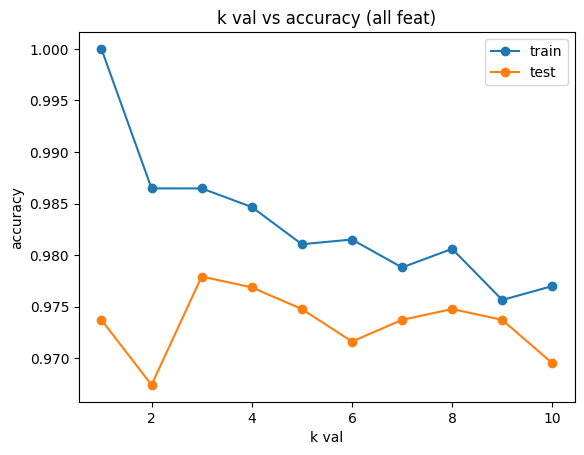

In [ ]:
acc_train, acc_test = [], []
for k in range(1, 11):
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_sc, y_train)
  acc_train.append(model.score(X_train_sc, y_train))
  acc_test.append(model.score(X_test_sc, y_test))

plt.plot(range(1, 11), acc_train, marker='o', label='train')
plt.plot(range(1, 11), acc_test, marker='o', label='test')
plt.title('k val vs accuracy (all feat)')
plt.xlabel('k val')
plt.ylabel('accuracy')
plt.legend()
plt.show()

In [37]:
def uji_knn(fitur, k=3):
  scaler = StandardScaler()
  Xtr = scaler.fit_transform(X_train[fitur])
  Xte = scaler.transform(X_test[fitur])
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(Xtr, y_train)
  return model.score(Xtr, y_train), model.score(Xte, y_test)

print(uji_knn(list(X.columns), k=3))

(0.986468200270636, 0.9768664563617245)


In [38]:
score = {}
for f in X.columns:
  score[f] = uji_knn([f])[1]

rank = pd.Series(score).sort_values(ascending=False)
print(rank)

meanfun     0.940063
IQR         0.887487
Q25         0.858044
sd          0.785489
sp.ent      0.716088
sfm         0.652997
mode        0.635121
meanfreq    0.614090
centroid    0.614090
mindom      0.608833
median      0.592008
maxdom      0.573081
skew        0.568875
dfrange     0.566772
meandom     0.562566
kurt        0.558360
minfun      0.548896
modindx     0.522608
Q75         0.517350
maxfun      0.500526
dtype: float64


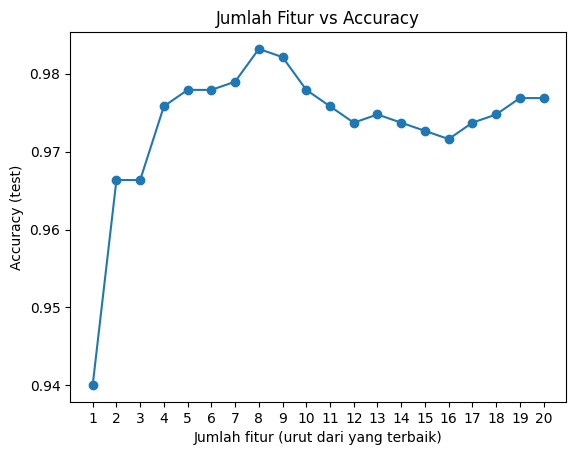

Jumlah fitur terbaik: 8
Fitur terbaik: ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'sfm', 'mode', 'meanfreq']
Accuracy test: 0.9831756046267087


In [39]:
hasil = []
for n in range(1, len(rank) + 1):
    fitur_n = list(rank.index[:n])
    hasil.append(uji_knn(fitur_n)[1])

plt.plot(range(1, len(hasil) + 1), hasil, marker='o')
plt.title('Jumlah Fitur vs Accuracy')
plt.xlabel('Jumlah fitur (urut dari yang terbaik)')
plt.ylabel('Accuracy (test)')
plt.xticks(range(1, len(hasil) + 1))
plt.show()

n_terbaik = hasil.index(max(hasil)) + 1
fitur_terbaik = list(rank.index[:n_terbaik])
print("Jumlah fitur terbaik:", n_terbaik)
print("Fitur terbaik:", fitur_terbaik)
print("Accuracy test:", max(hasil))

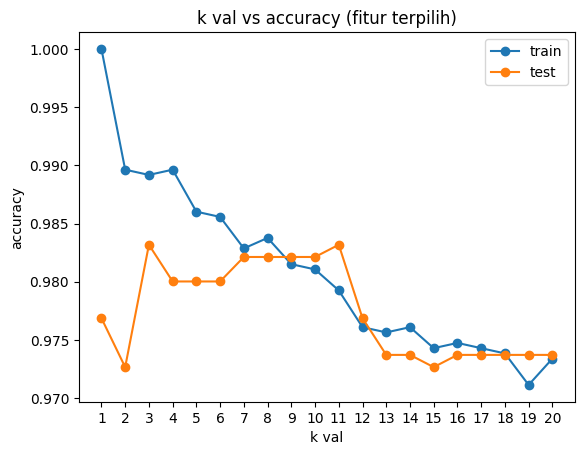

k terbaik: 3
Accuracy test: 0.9831756046267087


In [40]:
daftar_k = range(1, 21)
acc_train, acc_test = [], []

for k in daftar_k:
    tr, te = uji_knn(fitur_terbaik, k)
    acc_train.append(tr)
    acc_test.append(te)

plt.plot(daftar_k, acc_train, marker='o', label='train')
plt.plot(daftar_k, acc_test, marker='o', label='test')
plt.title('k val vs accuracy (fitur terpilih)')
plt.xlabel('k val')
plt.ylabel('accuracy')
plt.xticks(daftar_k)
plt.legend()
plt.show()

k_terbaik = daftar_k[acc_test.index(max(acc_test))]
print("k terbaik:", k_terbaik)
print("Accuracy test:", max(acc_test))

In [41]:
sc = StandardScaler()
Xtr = sc.fit_transform(X_train[fitur_terbaik])
Xte = sc.transform(X_test[fitur_terbaik])

knn_final = KNeighborsClassifier(n_neighbors=k_terbaik)
knn_final.fit(Xtr, y_train)
y_pred_final = knn_final.predict(Xte)

print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_final))
print("Classification Report:\n", classification_report(y_test, y_pred_final))

Accuracy: 0.9831756046267087
Confusion Matrix:
 [[447   5]
 [ 11 488]]
Classification Report:
               precision    recall  f1-score   support

      female       0.98      0.99      0.98       452
        male       0.99      0.98      0.98       499

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



# LAB ASSIGNMENT 2

In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [43]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/datasets/spam.csv", encoding='latin-1')
print(df.head())

     v1  ... Unnamed: 4
0   ham  ...        NaN
1   ham  ...        NaN
2  spam  ...        NaN
3   ham  ...        NaN
4   ham  ...        NaN

[5 rows x 5 columns]


In [44]:
df = df[['v1', 'v2']]
df.columns = ['label', 'sms']

print(df['label'].value_counts())
df.info()

df['label'] = df['label'].map({'ham': 0, 'spam': 1})
X = df['sms']
y = df['label']

label
ham     4825
spam     747
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   sms     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [50]:
def train_and_eval(vectorizer, name):
  Xtr = vectorizer.fit_transform(X_train)
  Xte = vectorizer.transform(X_test)

  print("jumlah fitur (words):" , len(vectorizer.get_feature_names_out()))
  print("dimensi data train", Xtr.shape)

  model = MultinomialNB()
  model.fit(Xtr, y_train)

  pred_train = model.predict(Xtr)
  pred_test = model.predict(Xte)

  print("Training accuracy:", accuracy_score(y_train, pred_train))
  print("Test accuracy:", accuracy_score(y_test, pred_test))
  print("Confusion Matrix:\n", confusion_matrix(y_test, pred_test))
  print("Classification Report:\n", classification_report(y_test, pred_test))

  return {
    'Fitur': name,
    'Train acc': accuracy_score(y_train, pred_train),
    'Test acc': accuracy_score(y_test, pred_test),
    'Precision spam': precision_score(y_test, pred_test),
    'Recall spam': recall_score(y_test, pred_test),
    'F1 spam': f1_score(y_test, pred_test),
  }

In [51]:
hasil_bow = train_and_eval(CountVectorizer(stop_words='english'), "CountVectorizer")

hasil_tfidf = train_and_eval(TfidfVectorizer(stop_words='english'), "TF-IDF")

jumlah fitur (words): 7472
dimensi data train (4457, 7472)
Training accuracy: 0.9946152120260264
Test accuracy: 0.9838565022421525
Confusion Matrix:
 [[959   6]
 [ 12 138]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       965
           1       0.96      0.92      0.94       150

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115

jumlah fitur (words): 7472
dimensi data train (4457, 7472)
Training accuracy: 0.9838456360780794
Test accuracy: 0.9668161434977578
Confusion Matrix:
 [[965   0]
 [ 37 113]]
Classification Report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98       965
           1       1.00      0.75      0.86       150

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighte

In [52]:
compare = pd.DataFrame([hasil_bow, hasil_tfidf]).round(4)
print(compare.to_string(index=False))

          Fitur  Train acc  Test acc  Precision spam  Recall spam  F1 spam
CountVectorizer     0.9946    0.9839          0.9583       0.9200   0.9388
         TF-IDF     0.9838    0.9668          1.0000       0.7533   0.8593
